# 03 · Caracterización temporal y espectral del precio de bolsa

**Objetivo (OE1 del Anexo 1).** Describir el precio de bolsa horario de Colombia como una señal: su nivel y dispersión,
sus ciclos (diario, semanal y anual), su relación con el fenómeno de El Niño, su contenido en frecuencia y la mejor
forma de separar su tendencia. Estos hallazgos justifican las variables del modelo (hora, día de la semana, hidrología,
ONI) y el diseño del motor de decisión.

**Datos.** Precio de bolsa nacional, demanda real, generación, volumen útil de embalses y aportes hídricos de XM, e
índice ONI de NOAA, de enero de 2019 hasta el último precio que XM ha publicado. Se unen dos fuentes que no se modifican:

| Tramo | Archivo | Origen |
|---|---|---|
| ene-2019 a 5-ago-2026 | `data/processed/dataset_maestro_*.csv` | Dataset oficial del proyecto (periodo del informe final) |
| 6-ago-2026 en adelante | `data/produccion/serie_xm.csv` | Operación diaria (GitHub Actions) |

Las cifras de este notebook incluyen la operación, así que pueden diferir de las del informe final, que se cortan en
el 5 de agosto de 2026. El notebook solo lee datos: no escribe nada en `data/`.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import signal
from scipy.signal import savgol_filter, butter, filtfilt

warnings.filterwarnings("ignore")
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(RAIZ / "scripts_experimento"))

# paleta validada (la misma de las figuras del informe): azul, naranja y aqua; texto en grises
AZUL, NARANJA, AQUA, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#6b6a66", "#1f1f1e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "#b9b8b2", "axes.labelcolor": TINTA,
                     "xtick.color": GRIS, "ytick.color": GRIS, "legend.frameon": False, "lines.linewidth": 1.4})
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre",
         "diciembre"]
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\mgdbj\xm-spot-price-predictor


## 1. Carga y verificación de los datos
Se concatena el dataset oficial con la operación diaria y se recorta en la última hora con precio publicado. Las
variables diarias (embalses y aportes) vienen repetidas en las 24 horas del día.

In [2]:
oficial = pd.concat([pd.read_csv(RAIZ / "data/processed" / f, parse_dates=["fecha_hora"])
                     for f in ("dataset_maestro_2019_2025.csv", "dataset_maestro_2026.csv")])
operacion = pd.read_csv(RAIZ / "data/produccion/serie_xm.csv", parse_dates=["fecha_hora"])
corte_oficial = oficial["fecha_hora"].max()
df = (pd.concat([oficial, operacion[operacion["fecha_hora"] > corte_oficial]])
        .drop_duplicates("fecha_hora").set_index("fecha_hora").sort_index())
FIN = df["precio_bolsa"].last_valid_index()
df = df.loc[:FIN]
precio = df["precio_bolsa"]
# dias con la demanda aun parcial: XM publica primero un valor incompleto del ultimo dia y lo completa despues
# (el 1-nov-2026 la demanda era 28 % de la generacion). Se descartan si la demanda queda bajo el 90 % de la generacion.
razon = (df["demanda"] / df["generacion"]).groupby(df.index.normalize()).transform("mean")
DIAS_PARCIALES = sorted(set(df.index[razon < 0.9].normalize().strftime("%d/%m/%Y")))
df.loc[razon < 0.9, "demanda"] = np.nan


horas_esperadas = pd.date_range(df.index.min(), FIN, freq="h")
print(f"Periodo: {df.index.min():%d/%m/%Y %H:%M} a {FIN:%d/%m/%Y %H:%M}")
print(f"Horas: {len(df):,} de {len(horas_esperadas):,} esperadas | faltantes: {len(horas_esperadas.difference(df.index))} | "
      f"duplicadas: {df.index.duplicated().sum()}")
print(f"Tramo oficial hasta {corte_oficial:%d/%m/%Y}; operación: {(df.index > corte_oficial).sum():,} horas más")
print("Días con la demanda aún parcial (se descartan en los análisis de demanda):", DIAS_PARCIALES or "ninguno")
print("Valores vacíos por variable:")
print(df[["precio_bolsa", "demanda", "generacion", "volumen_embalses", "aportes_hidricos"]].isna().sum().to_string())

Periodo: 01/01/2019 00:00 a 07/11/2026 23:00
Horas: 68,832 de 68,832 esperadas | faltantes: 0 | duplicadas: 0
Tramo oficial hasta 05/08/2026; operación: 2,256 horas más
Días con la demanda aún parcial (se descartan en los análisis de demanda): ['06/11/2026', '07/11/2026']
Valores vacíos por variable:
precio_bolsa         0
demanda             48
generacion           0
volumen_embalses     0
aportes_hidricos     0


**ONI.** NOAA publica cada trimestre móvil (por ejemplo, ASO = agosto-septiembre-octubre) a inicios del mes siguiente.
El archivo de producción rellena los trimestres aún no publicados con el último valor, para que el modelo tenga la
variable; aquí solo se usan los trimestres ya publicados a la fecha del último precio.

In [3]:
oni_ancho = pd.read_csv(RAIZ / "data/produccion/oni_index.csv")
TRIM = ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"]
oni = (oni_ancho.melt(id_vars="anio", value_vars=TRIM, var_name="trim", value_name="oni")
       .assign(mes_central=lambda t: t["trim"].map({k: i + 1 for i, k in enumerate(TRIM)})))
oni["fecha"] = pd.to_datetime(dict(year=oni["anio"], month=oni["mes_central"], day=1))
# publicado: el trimestre termina (mes central + 1) antes del mes del ultimo precio
oni = oni[oni["fecha"] + pd.DateOffset(months=1) < FIN.to_period("M").to_timestamp()].dropna(subset=["oni"])
oni = oni.set_index("fecha")["oni"].sort_index().loc["2019-01-01":]
print(f"ONI publicado hasta el trimestre centrado en {oni.index[-1]:%m/%Y}: {oni.iloc[-1]:+.1f}")
print(oni.loc["2025-10-01":].to_string())

ONI publicado hasta el trimestre centrado en 09/2026: +2.5
fecha
2025-10-01   -0.6
2025-11-01   -0.6
2025-12-01   -0.6
2026-01-01   -0.4
2026-02-01   -0.2
2026-03-01    0.1
2026-04-01    0.5
2026-05-01    1.0
2026-06-01    1.4
2026-07-01    1.8
2026-08-01    2.2
2026-09-01    2.5


## 2. Estadística descriptiva
El precio de bolsa es asimétrico: tiene una cola larga hacia arriba en las épocas de escasez. Por eso, además de la
media, se reportan la mediana, los percentiles altos y el coeficiente de variación por año.

In [4]:
por_anio = precio.groupby(precio.index.year).agg(
    media="mean", mediana="median", p05=lambda s: s.quantile(.05), p95=lambda s: s.quantile(.95), maximo="max",
    desv="std")
por_anio["CV %"] = por_anio["desv"] / por_anio["media"] * 100
por_anio.index.name = "año"
todo = precio.describe(percentiles=[.05, .25, .5, .75, .95])
print(f"Todo el periodo: media {todo['mean']:,.1f}, mediana {todo['50%']:,.1f}, p95 {todo['95%']:,.1f}, "
      f"máximo {todo['max']:,.1f} COP/kWh | asimetría {precio.skew():.2f}")
por_anio.drop(columns="desv").round(1)

Todo el periodo: media 348.7, mediana 249.1, p95 953.8, máximo 2,675.6 COP/kWh | asimetría 2.46


,media,mediana,p05,p95,maximo,CV %
año,,,,,,
2019,228.3,220.8,84.3,390.0,910.5,42.6
2020,251.1,217.1,109.5,461.6,745.5,45.2
2021,150.1,108.0,87.1,325.7,592.9,62.7
2022,215.8,200.1,97.2,476.6,1035.1,58.8
2023,558.1,499.4,138.7,1062.0,1595.7,54.1
2024,676.1,590.0,147.2,1751.8,2675.6,69.4
2025,240.3,163.9,104.8,701.7,2224.0,77.8
2026,490.1,414.1,112.3,1038.1,1902.6,64.3


## 3. La serie completa y El Niño
Promedio diario del precio con su media móvil de 30 días. Las franjas marcan los trimestres con ONI ≥ 0,5 (El Niño) y
ONI ≤ −0,5 (La Niña).

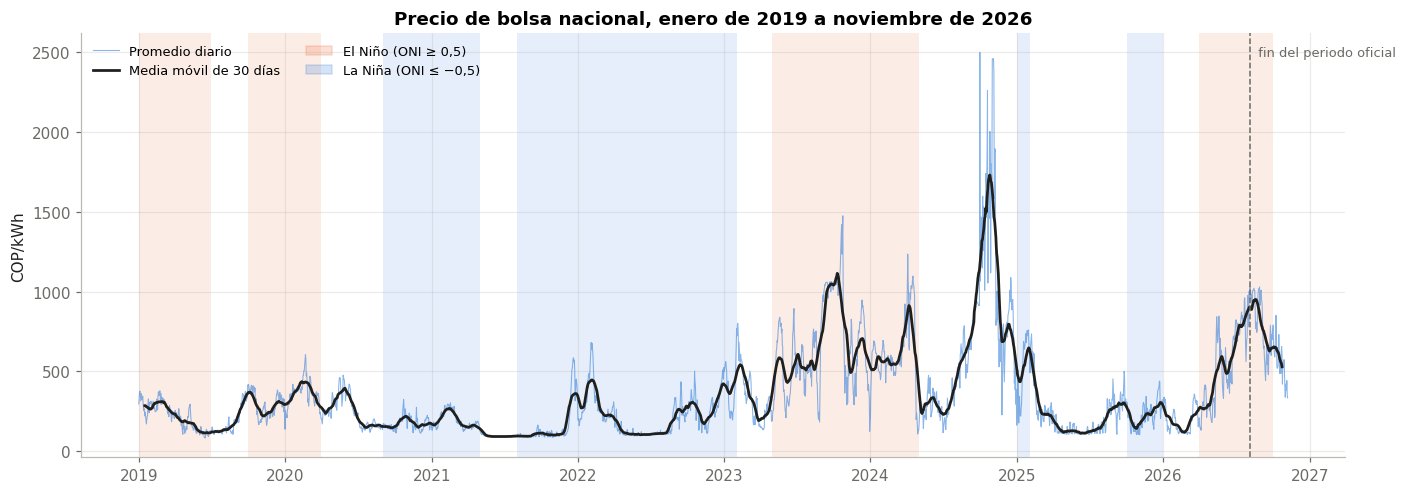

,media,mediana,días
El Niño,496.4,428.7,951
La Niña,212.4,177.4,914
Neutral,332.8,222.1,1003


In [5]:
def franjas_enso(ax):
    # una franja continua por cada racha de meses con el mismo signo (cada trimestre se asigna a su mes central)
    signo = np.sign(oni.where(oni.abs() >= 0.5, 0))
    racha = (signo != signo.shift()).cumsum()
    for _, g in signo.groupby(racha):
        if g.iloc[0] != 0:
            ax.axvspan(g.index[0], g.index[-1] + pd.offsets.MonthBegin(1), lw=0,
                       color=NARANJA if g.iloc[0] > 0 else AZUL, alpha=0.12)

diario = precio.resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 4.6))
franjas_enso(ax)
ax.plot(diario.index, diario, color=AZUL, lw=0.7, alpha=0.55, label="Promedio diario")
ax.plot(diario.index, diario.rolling(30, center=True).mean(), color=TINTA, lw=1.8, label="Media móvil de 30 días")
ax.axvline(corte_oficial, color=GRIS, ls="--", lw=1)
ax.text(corte_oficial, ax.get_ylim()[1] * 0.97, "  fin del periodo oficial", color=GRIS, fontsize=8.5, va="top")
ax.set_ylabel("COP/kWh")
ax.set_title(f"Precio de bolsa nacional, enero de 2019 a {MESES[FIN.month - 1]} de {FIN.year}")
ax.legend(handles=ax.get_legend_handles_labels()[0] + [plt.Rectangle((0, 0), 1, 1, color=NARANJA, alpha=.2),
                                                        plt.Rectangle((0, 0), 1, 1, color=AZUL, alpha=.2)],
          labels=["Promedio diario", "Media móvil de 30 días", "El Niño (ONI ≥ 0,5)", "La Niña (ONI ≤ −0,5)"],
          loc="upper left", ncol=2, fontsize=8.5)
plt.tight_layout(); plt.show()

episodios = diario.groupby(np.select([diario.index.map(lambda d: oni.asof(d) if d >= oni.index[0] else np.nan) >= .5,
                                      diario.index.map(lambda d: oni.asof(d) if d >= oni.index[0] else np.nan) <= -.5],
                                     ["El Niño", "La Niña"], "Neutral")).agg(["mean", "median", "count"])
episodios.columns = ["media", "mediana", "días"]
episodios.round(1)

## 4. Ciclo diario: precio y demanda
El ciclo diario del precio sigue el de la demanda: sube con la actividad de la mañana, tiene un tramo intermedio al
mediodía y su máximo en el pico nocturno, cuando entra la iluminación residencial. El fin de semana la demanda baja y
el precio también. Se muestran la mediana por hora y la banda entre los percentiles 25 y 75.

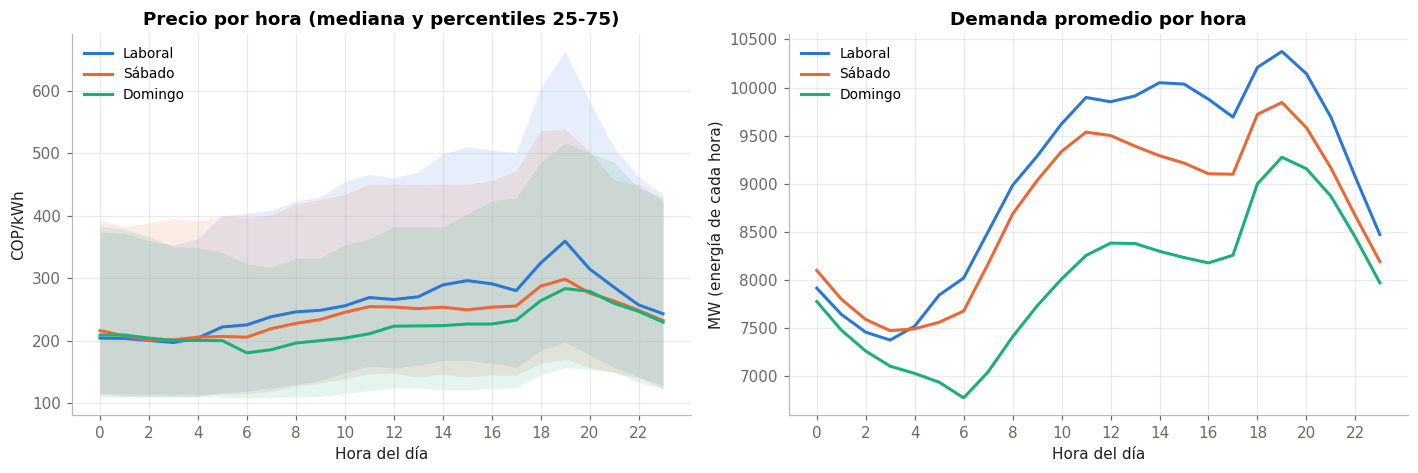

Día laboral: precio máximo a las 19 h (473) y mínimo a las 03 h (290); demanda máxima a las 19 h.
Correlación entre el perfil horario de precio y el de demanda: 0.90
Frente a un día laboral: sábado -3.8% de demanda y -4.6% de precio; domingo -12.0% y -11.9%.


In [6]:
tipo = np.where(df.index.dayofweek < 5, "Laboral", np.where(df.index.dayofweek == 5, "Sábado", "Domingo"))
colores = {"Laboral": AZUL, "Sábado": NARANJA, "Domingo": AQUA}
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for nombre, color in colores.items():
    sub = df[tipo == nombre]
    g = sub.groupby(sub.index.hour)
    axs[0].plot(range(24), g["precio_bolsa"].median(), color=color, lw=2, label=nombre)
    axs[0].fill_between(range(24), g["precio_bolsa"].quantile(.25), g["precio_bolsa"].quantile(.75), color=color, alpha=.12, lw=0)
    axs[1].plot(range(24), g["demanda"].mean() / 1e3, color=color, lw=2, label=nombre)
axs[0].set_title("Precio por hora (mediana y percentiles 25-75)"); axs[0].set_ylabel("COP/kWh")
axs[1].set_title("Demanda promedio por hora"); axs[1].set_ylabel("MW (energía de cada hora)")
for ax in axs:
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hora del día"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

lab = df[tipo == "Laboral"]
perfil_p = lab.groupby(lab.index.hour)["precio_bolsa"].mean()
perfil_d = lab.groupby(lab.index.hour)["demanda"].mean()
print(f"Día laboral: precio máximo a las {perfil_p.idxmax():02d} h ({perfil_p.max():,.0f}) y mínimo a las "
      f"{perfil_p.idxmin():02d} h ({perfil_p.min():,.0f}); demanda máxima a las {perfil_d.idxmax():02d} h.")
print(f"Correlación entre el perfil horario de precio y el de demanda: {np.corrcoef(perfil_p, perfil_d)[0, 1]:.2f}")
med = df.groupby(tipo)[["precio_bolsa", "demanda"]].mean()
print(f"Frente a un día laboral: sábado {med.loc['Sábado', 'demanda'] / med.loc['Laboral', 'demanda'] - 1:+.1%} de demanda y "
      f"{med.loc['Sábado', 'precio_bolsa'] / med.loc['Laboral', 'precio_bolsa'] - 1:+.1%} de precio; domingo "
      f"{med.loc['Domingo', 'demanda'] / med.loc['Laboral', 'demanda'] - 1:+.1%} y "
      f"{med.loc['Domingo', 'precio_bolsa'] / med.loc['Laboral', 'precio_bolsa'] - 1:+.1%}.")

## 5. Ciclo anual
Precio promedio de cada mes de cada año. Los colores son los del mapa de calor del precio de bolsa de XM (Sinergox): azul en el mes más barato, crema en el
precio medio de la tabla y naranja-rojo en el más caro.

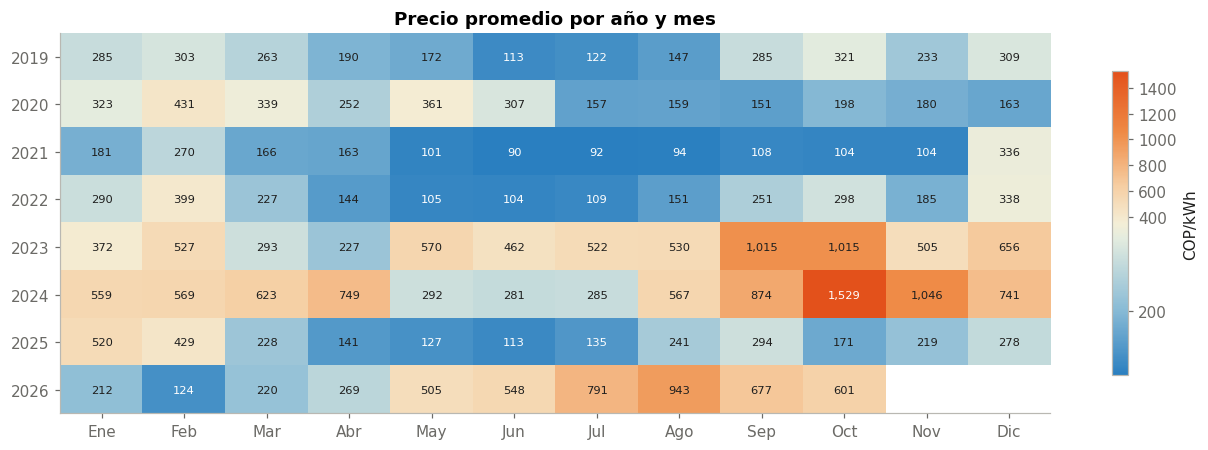

In [7]:
g_mes = precio.groupby([precio.index.year, precio.index.month])
tabla = g_mes.mean().where(g_mes.size() >= 20 * 24).unstack()      # meses con menos de 20 dias de datos: vacios
tabla.index.name, tabla.columns.name = "año", "mes"
# escala del mapa de calor del precio de bolsa en Sinergox (XM), la misma del dashboard: azul en el minimo,
# crema en el valor medio y naranja-rojo en el maximo
escala_xm = LinearSegmentedColormap.from_list("xm", [(0.0, "#2A7FC0"), (0.22, "#8BBCD6"), (0.45, "#E4ECDF"),
                                                     (0.5, "#F4EED6"), (0.62, "#F6CFA4"), (0.8, "#EF8A45"),
                                                     (1.0, "#E3511B")])
azules = LinearSegmentedColormap.from_list("azules", ["#e8f1fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])  # espectrograma
valores = tabla.to_numpy()
norma = TwoSlopeNorm(vmin=np.nanmin(valores), vcenter=np.nanmean(valores), vmax=np.nanmax(valores))
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(valores, cmap=escala_xm, norm=norma, aspect="auto")
ax.set_xticks(range(12), ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_yticks(range(len(tabla)), tabla.index); ax.grid(False)
for (i, j), v in np.ndenumerate(valores):
    if not np.isnan(v):
        r, g, b, _ = escala_xm(norma(v))
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=7.5,
                color="white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.55 else TINTA)
fig.colorbar(im, ax=ax, label="COP/kWh", shrink=.8)
ax.set_title("Precio promedio por año y mes")
plt.tight_layout(); plt.show()

## 6. Relación con el ONI
Precio promedio mensual frente al ONI con distintos rezagos. Un rezago de *k* meses compara el ONI de hace *k* meses con
el precio de hoy: mide cuánto tarda El Niño en llegar al precio, a través de los aportes y los embalses. Ojo: cada ONI
es un promedio de tres meses centrado en su mes, así que el rezago 0 ya incluye el mes siguiente; en tiempo real el ONI
llega con unos dos meses de retraso.

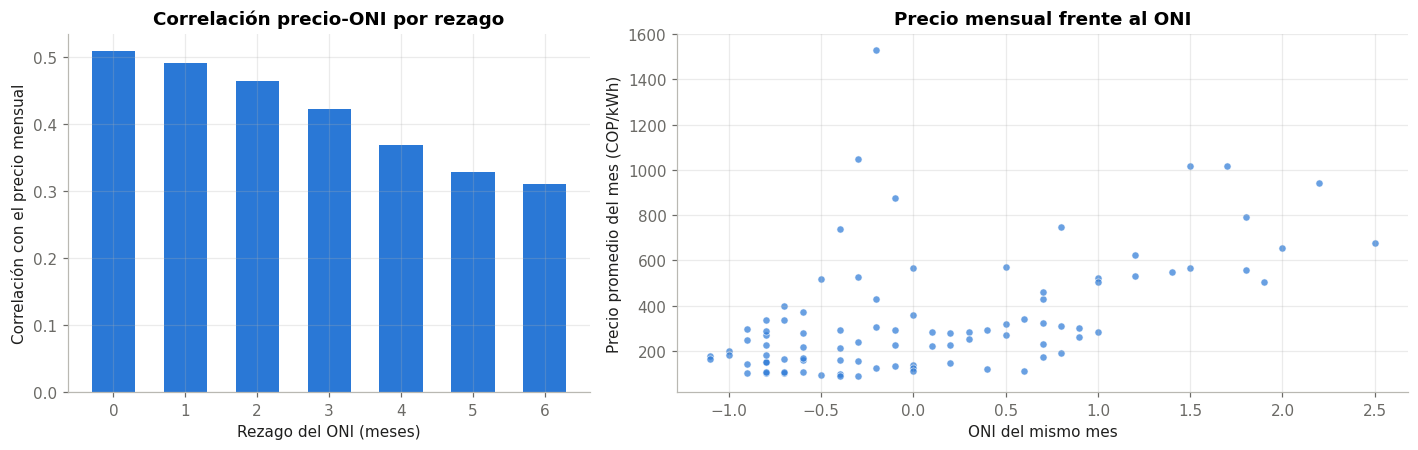

rezago (meses),0,1,2,3,4,5,6
correlación,0.509,0.491,0.463,0.421,0.369,0.328,0.311


In [8]:
mensual = precio.resample("MS").mean()
rezagos = range(0, 7)
corr_oni = pd.Series({k: mensual.corr(oni.shift(k).reindex(mensual.index)) for k in rezagos}, name="correlación")
corr_oni.index.name = "rezago (meses)"
mejor = corr_oni.idxmax()
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
axs[0].bar(corr_oni.index, corr_oni, color=AZUL, width=.6)
axs[0].set_xlabel("Rezago del ONI (meses)"); axs[0].set_ylabel("Correlación con el precio mensual")
axs[0].set_title("Correlación precio-ONI por rezago")
x = oni.shift(mejor).reindex(mensual.index)
axs[1].scatter(x, mensual, s=22, color=AZUL, alpha=.7, edgecolor="white", lw=.5)
axs[1].set_xlabel("ONI del mismo mes" if mejor == 0 else f"ONI de {mejor} meses antes")
axs[1].set_ylabel("Precio promedio del mes (COP/kWh)")
axs[1].set_title("Precio mensual frente al ONI" + ("" if mejor == 0 else f" con {mejor} meses de rezago"))
plt.tight_layout(); plt.show()
corr_oni.to_frame().T.round(3)

## 7. Contenido en frecuencia
Para ver los ciclos sin que la tendencia de largo plazo domine el espectro, primero se le resta la tendencia
(Savitzky-Golay de 721 horas, sección 9) y luego se estima la densidad espectral de potencia con el método de Welch
(ventanas de 16 semanas con 50 % de traslape, Hann). Con una muestra por hora (fs = 1/h), un pico en la frecuencia *f*
corresponde a un ciclo de 1/*f* horas.

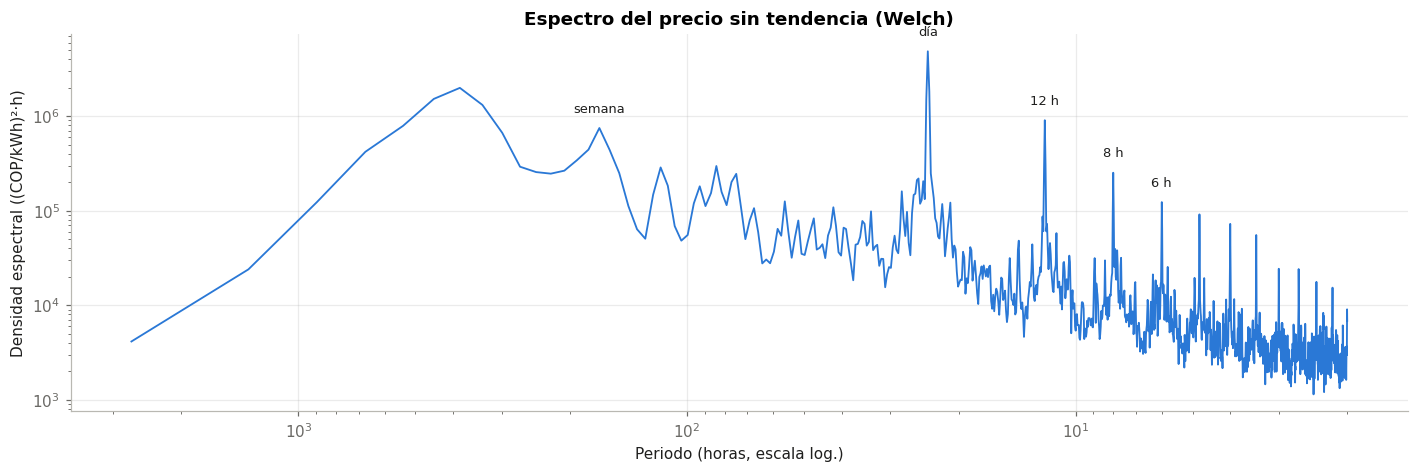

,periodo (h),potencia,potencia relativa al ciclo diario
0,24.0,4847991.0,1.000
1,12.0,904775.0,0.187
2,168.0,748301.0,0.154
3,84.0,296637.0,0.061
4,116.9,286607.0,0.059
5,8.0,251820.0,0.052


In [9]:
y = precio.interpolate().to_numpy(float)
tendencia_sg = savgol_filter(y, 721, 3)
residuo = y - tendencia_sg
f, pxx = signal.welch(residuo, fs=1.0, window="hann", nperseg=24 * 7 * 16, noverlap=24 * 7 * 8, detrend="constant")
periodo = 1 / f[1:]
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.loglog(periodo, pxx[1:], color=AZUL, lw=1.2)
ax.invert_xaxis()
for p, nombre in ((168, "semana"), (24, "día"), (12, "12 h"), (8, "8 h"), (6, "6 h")):
    i = np.argmin(abs(periodo - p))
    ax.annotate(nombre, (periodo[i], pxx[1:][i]), xytext=(0, 10), textcoords="offset points", ha="center",
                fontsize=8.5, color=TINTA)
ax.set_xlabel("Periodo (horas, escala log.)"); ax.set_ylabel("Densidad espectral ((COP/kWh)²·h)")
ax.set_title("Espectro del precio sin tendencia (Welch)")
plt.tight_layout(); plt.show()

# picos de los ciclos de hasta 200 h (por encima, el espectro refleja lo que queda de la tendencia)
picos, _ = signal.find_peaks(np.log(pxx[1:]), prominence=1.0)
picos = picos[periodo[picos] <= 200]
tabla_picos = (pd.DataFrame({"periodo (h)": periodo[picos], "potencia": pxx[1:][picos]})
               .sort_values("potencia", ascending=False).head(6))
tabla_picos["potencia relativa al ciclo diario"] = tabla_picos["potencia"] / pxx[1:][np.argmin(abs(periodo - 24))]
tabla_picos.round({"periodo (h)": 1, "potencia": 0, "potencia relativa al ciclo diario": 3}).reset_index(drop=True)

### 7.1 ¿Cambia el ciclo diario con el tiempo?
El espectro anterior promedia todo el periodo. Un espectrograma (transformada de Fourier en ventanas de 4 semanas que
avanzan una semana) muestra cómo cambia en el tiempo la amplitud del ciclo diario y la de su armónico de 12 h.

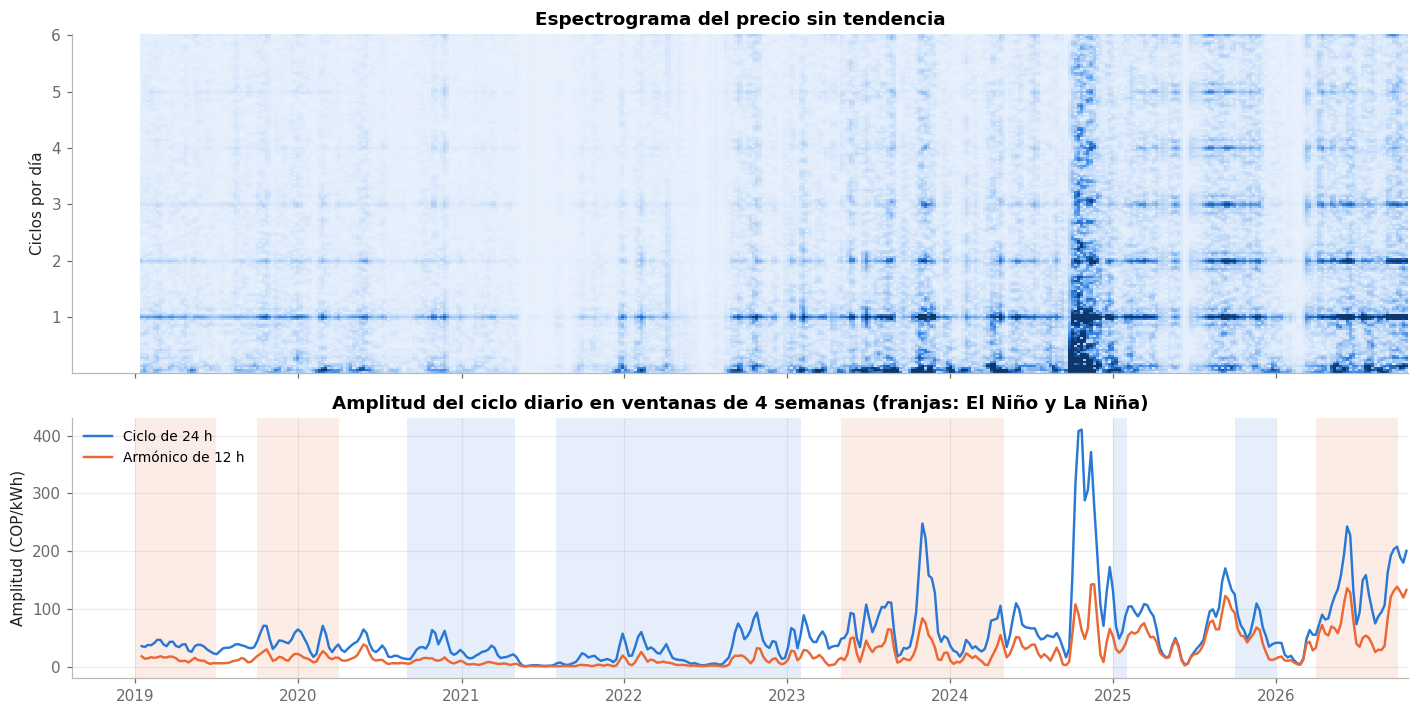

Amplitud media del ciclo diario: El Niño 75 | neutral 65 | La Niña 32 COP/kWh
Máxima: 410 COP/kWh en la ventana que termina el 05/11/2024


In [10]:
nper = 24 * 28
f_s, t_s, Z = signal.stft(residuo, fs=1.0, window="hann", nperseg=nper, noverlap=nper - 24 * 7, detrend="constant",
                          boundary=None, padded=False)
fechas_s = precio.index[0] + pd.to_timedelta(t_s, unit="h")
amp = 2 * np.abs(Z)       # stft ya normaliza por la suma de la ventana: 2|Z| es la amplitud de cada componente
i24, i12 = np.argmin(abs(f_s - 1 / 24)), np.argmin(abs(f_s - 1 / 12))
fig, axs = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
banda = (f_s > 0) & (f_s <= 1 / 4)
axs[0].pcolormesh(fechas_s, f_s[banda] * 24, amp[banda], cmap=azules, shading="auto",
                  vmax=np.percentile(amp[banda], 99.5))
axs[0].set_ylabel("Ciclos por día"); axs[0].set_title("Espectrograma del precio sin tendencia"); axs[0].grid(False)
franjas_enso(axs[1])
axs[1].plot(fechas_s, amp[i24], color=AZUL, lw=1.6, label="Ciclo de 24 h")
axs[1].plot(fechas_s, amp[i12], color=NARANJA, lw=1.6, label="Armónico de 12 h")
axs[1].set_ylabel("Amplitud (COP/kWh)"); axs[1].legend(loc="upper left", fontsize=9)
axs[1].set_title("Amplitud del ciclo diario en ventanas de 4 semanas (franjas: El Niño y La Niña)")
plt.tight_layout(); plt.show()

a24 = pd.Series(amp[i24], index=fechas_s)
oni_v = a24.index.map(lambda d: oni.asof(d))
print(f"Amplitud media del ciclo diario: El Niño {a24[oni_v >= .5].mean():.0f} | neutral "
      f"{a24[(oni_v > -.5) & (oni_v < .5)].mean():.0f} | La Niña {a24[oni_v <= -.5].mean():.0f} COP/kWh")
print(f"Máxima: {a24.max():.0f} COP/kWh en la ventana que termina el {a24.idxmax() + pd.Timedelta(days=14):%d/%m/%Y}")

## 8. Tendencia: ¿qué filtro usar?
La tendencia separa el nivel de largo plazo de los ciclos cortos. Se comparan cinco filtros fuera de línea (usan pasado
y futuro, sirven para caracterizar) y cinco causales (solo pasado, usables en tiempo real), con las funciones de
`scripts_experimento/comparar_filtros_tendencia.py`.

Comparar cada filtro con un solo ajuste sería injusto: el que suaviza menos siempre reacciona antes. Por eso cada
familia se recorre en su parámetro de suavizado y se compara **al mismo nivel de suavizado** que el Savitzky-Golay de
721 h (la misma «fuga» de ciclos cortos en la tendencia). Gana el que llega antes al 90 % de la subida de El Niño. Ahora
hay dos eventos para medirlo:

- **El Niño 2023-2024** (subida rápida): la medida del notebook original, horas desde 60 días antes del pico hasta que
  la tendencia alcanza el 90 % de la subida.
- **El Niño 2026** (subida gradual, de marzo a agosto): horas desde el 1 de abril de 2026, cuando el ONI pasó de 0,5,
  hasta que la tendencia alcanza el 90 % del paso entre el nivel de febrero-marzo y el de mediados de julio a agosto.

In [11]:
import comparar_filtros_tendencia as cf
get_ipython().run_line_magic("matplotlib", "inline")   # el script pone matplotlib en modo sin pantalla al importarse

p = precio.interpolate()
cf.REF = filtfilt(*butter(2, 2.0 / 720), p.to_numpy(float))       # referencia sin desfase para el retraso medio
cf.ZOOM = slice("2023-06-01", "2024-03-01")


def metricas_2026(p, tend):
    # como cf.metricas, pero con el evento gradual de 2026 (ver el texto de arriba)
    tend = pd.Series(np.asarray(tend, float), index=p.index)
    previo, nivel = p.loc["2026-02-01":"2026-03-31"].mean(), p.loc["2026-07-15":"2026-08-31"].mean()
    umbral, inicio = previo + 0.9 * (nivel - previo), pd.Timestamp("2026-04-01")
    cruce = tend.loc[inicio:][tend.loc[inicio:] >= umbral]
    retraso = (cruce.index[0] - inicio).total_seconds() / 3600 if len(cruce) else np.nan
    residuo = (p - tend).dropna().std()
    fuga = (tend - tend.rolling(168, center=True, min_periods=84).mean()).dropna().std()
    return retraso, residuo, fuga, cf.retraso_medio(tend.to_numpy(), cf.REF)


EVENTOS = {"El Niño 2023-2024": cf.metricas, "El Niño 2026": metricas_2026}
ZOOMS = {"El Niño 2023-2024": slice("2023-06-01", "2024-03-01"), "El Niño 2026": slice("2026-02-01", "2026-10-31")}
fl, ca = cf.familias(p)
filas = []
for evento, metrica in EVENTOS.items():
    ref = metrica(p, savgol_filter(p.to_numpy(float), 721, 3))
    for tipo_f, fams in (("Fuera de línea", fl), ("Causal", ca)):
        for nombre, (param, valores, fn) in fams.items():
            t = pd.DataFrame([dict(zip(("retraso", "residuo", "fuga", "retraso_medio_h"), metrica(p, fn(v))))
                              for v in valores])
            r, s, rm = cf.interpolar_a_fuga(t, ref[2])
            filas.append({"evento": evento, "tipo": tipo_f, "filtro": nombre,
                          "horas hasta el 90 % de la subida": r, "retraso medio (h)": rm, "residuo (COP/kWh)": s})
comparacion = pd.DataFrame(filas)
tabla_filtros = comparacion.pivot_table(index=["tipo", "filtro"], columns="evento",
                                        values="horas hasta el 90 % de la subida", sort=False)
ref_2026 = metricas_2026(p, p.rolling(168, center=True, min_periods=84).mean())[0]
print(f"Referencia El Niño 2026: el propio precio (media centrada de 7 días) cruza el umbral {ref_2026:,.0f} h después del "
      f"1 de abril; lo que pase de eso en la tabla es el retraso que agrega cada filtro.")
tabla_filtros.round(0)

Referencia El Niño 2026: el propio precio (media centrada de 7 días) cruza el umbral 2,511 h después del 1 de abril; lo que pase de eso en la tabla es el retraso que agrega cada filtro.


evento                                          El Niño 2023-2024  \
tipo           filtro                                               
Fuera de línea Promedio móvil centrado                      839.0   
               Savitzky-Golay (orden 3)                     348.0   
               Butterworth fase cero (orden 2)              386.0   
               Wavelet sym8 (aproximación)                  630.0   
               Kalman (suavizador RTS)                      408.0   
Causal         Promedio móvil causal                       1013.0   
               Media exponencial                           1281.0   
               Savitzky-Golay causal (orden 2)              599.0   
               Butterworth causal (orden 2)                 580.0   
               Kalman (filtro causal)                       665.0   

evento                                          El Niño 2026  
tipo           filtro                                         
Fuera de línea Promedio móvil centrado                2582.0  
               Savitzky-Golay (orden 3)               2836.0  
               Butterworth fase cero (orden 2)        2874.0  
               Wavelet sym8 (aproximación)            2479.0  
               Kalman (suavizador RTS)                2704.0  
Causal         Promedio móvil causal                  2758.0  
               Media exponencial                      2990.0  
               Savitzky-Golay causal (orden 2)        2674.0  
               Butterworth causal (orden 2)           2740.0  
               Kalman (filtro causal)                 2604.0

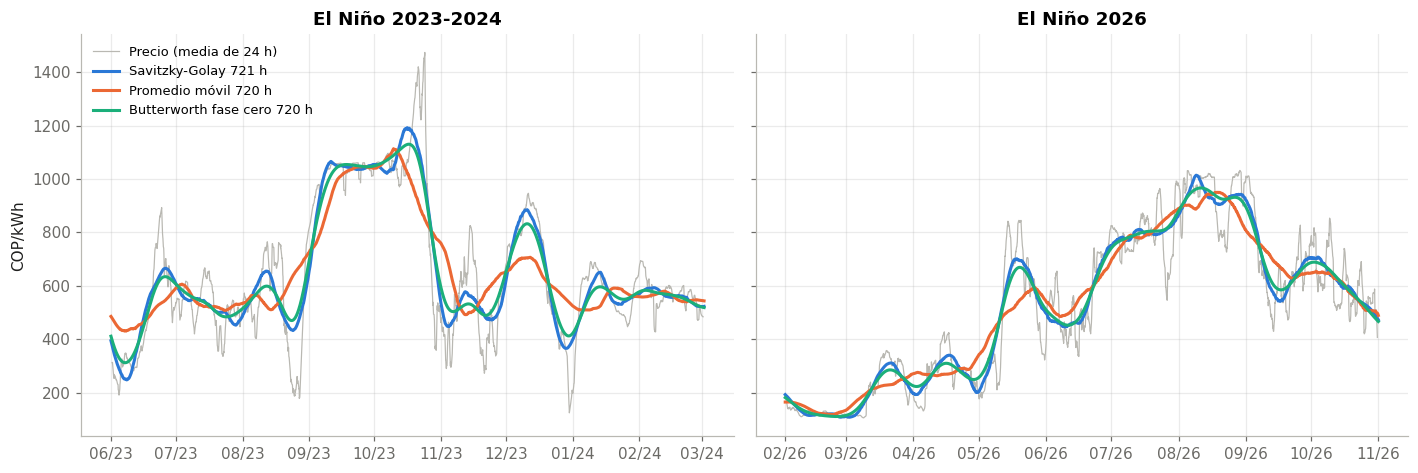

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (evento, zoom) in zip(axs, ZOOMS.items()):
    sub = p.loc[zoom]
    ax.plot(sub.index, sub.rolling(24, center=True).mean(), color="#b9b8b2", lw=.8, label="Precio (media de 24 h)")
    ax.plot(sub.index, pd.Series(savgol_filter(p.to_numpy(float), 721, 3), index=p.index).loc[zoom],
            color=AZUL, lw=2, label="Savitzky-Golay 721 h")
    ax.plot(sub.index, p.rolling(720, center=True, min_periods=360).mean().loc[zoom], color=NARANJA, lw=2,
            label="Promedio móvil 720 h")
    ax.plot(sub.index, pd.Series(filtfilt(*butter(2, 2.0 / 720), p.to_numpy(float)), index=p.index).loc[zoom],
            color=AQUA, lw=2, label="Butterworth fase cero 720 h")
    ax.set_title(evento); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
axs[0].set_ylabel("COP/kWh"); axs[0].legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()

## 9. Precio, demanda e hidrología
Correlación entre las variables del dataset maestro en promedios diarios (las diarias no se repiten 24 veces), y
correlación cruzada del precio con los aportes y los embalses con rezagos de 0 a 30 días: un rezago de *k* días compara
la hidrología de hace *k* días con el precio de hoy.

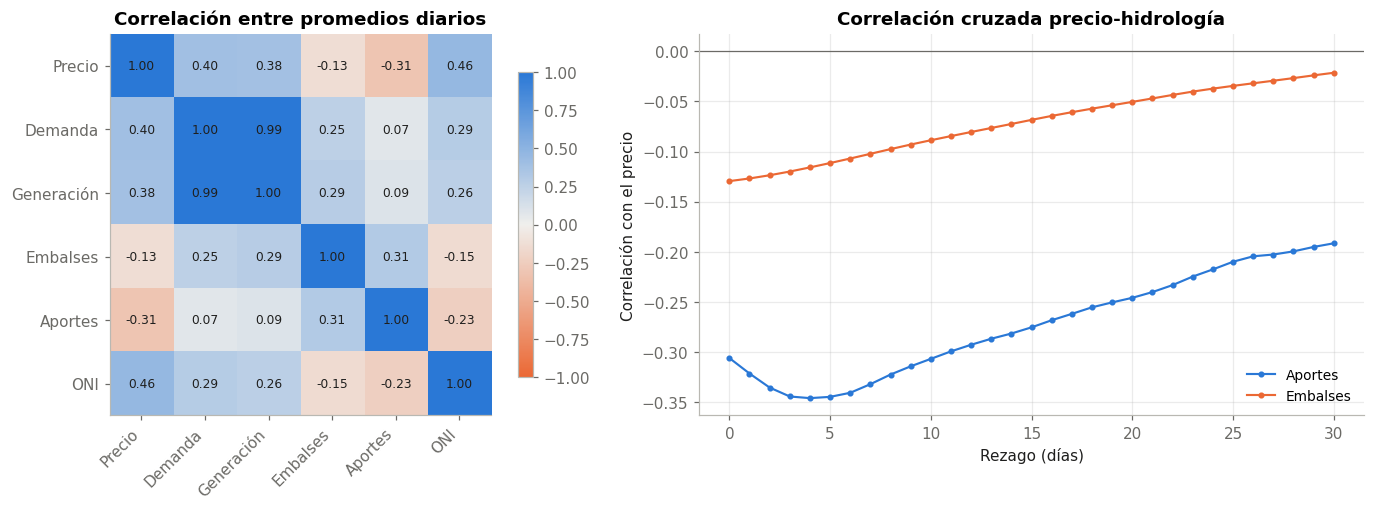

,Aportes,Embalses
rezago (días),,
0,-0.306,-0.129
1,-0.321,-0.127
7,-0.332,-0.102
14,-0.281,-0.072
30,-0.191,-0.021


In [13]:
d = df[["precio_bolsa", "demanda", "generacion", "volumen_embalses", "aportes_hidricos"]].resample("D").mean()
d["oni"] = d.index.map(lambda x: oni.asof(x) if x >= oni.index[0] else np.nan)
nombres = {"precio_bolsa": "Precio", "demanda": "Demanda", "generacion": "Generación",
           "volumen_embalses": "Embalses", "aportes_hidricos": "Aportes", "oni": "ONI"}
m = d.rename(columns=nombres).corr()
divergente = LinearSegmentedColormap.from_list("div", [NARANJA, "#f0efec", AZUL])
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
im = axs[0].imshow(m, cmap=divergente, vmin=-1, vmax=1); axs[0].grid(False)
axs[0].set_xticks(range(len(m)), m.columns, rotation=45, ha="right"); axs[0].set_yticks(range(len(m)), m.index)
for (i, j), v in np.ndenumerate(m.to_numpy()):
    axs[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color=TINTA)
axs[0].set_title("Correlación entre promedios diarios"); fig.colorbar(im, ax=axs[0], shrink=.8)
lags = range(0, 31)
for col, color in (("aportes_hidricos", AZUL), ("volumen_embalses", NARANJA)):
    axs[1].plot(lags, [d["precio_bolsa"].corr(d[col].shift(k)) for k in lags], "o-", ms=3, color=color,
                label=nombres[col])
axs[1].axhline(0, color=GRIS, lw=.8)
axs[1].set_xlabel("Rezago (días)"); axs[1].set_ylabel("Correlación con el precio")
axs[1].set_title("Correlación cruzada precio-hidrología"); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
cruz = pd.DataFrame({nombres[c]: [d["precio_bolsa"].corr(d[c].shift(k)) for k in lags] for c in ("aportes_hidricos", "volumen_embalses")},
                    index=pd.Index(lags, name="rezago (días)"))
cruz.loc[[0, 1, 7, 14, 30]].round(3)

## 10. Conclusiones
Cifras de la ejecución con datos hasta el 1 de noviembre de 2026 (68.688 horas, sin huecos ni duplicados).

1. **Señal asimétrica y de régimen cambiante.** La media (349 COP/kWh) está muy por encima de la mediana (249) y la
   asimetría es 2,5: la serie tiene una cola larga de precios altos. El nivel cambia por años (de 150 COP/kWh en 2021 a
   676 en 2024) y la variación dentro de cada año es grande (coeficiente de variación de 42 % a 78 %). Por eso el
   pronóstico necesita una banda de incertidumbre y no solo un valor, y el motor usa umbrales relativos (percentiles).
2. **El Niño sube el precio, pero no lo explica todo.** El precio diario promedia 497 COP/kWh en meses de El Niño, 333 en
   neutrales y 212 en La Niña, y la correlación con el ONI del mismo mes es 0,51 (baja a 0,31 con 6 meses de rezago).
   Pero el mes más caro del periodo, octubre de 2024 (1.529 COP/kWh), llegó con el ONI ya neutral, cuando los embalses
   seguían bajos tras El Niño 2023-2024: el estado hidrológico pesa tanto como el índice climático. Por eso el modelo usa
   el ONI junto con embalses y aportes.
3. **El ciclo diario sigue a la demanda.** En días laborales el precio y la demanda tienen su máximo a las 19 h (473
   COP/kWh en promedio) y el mínimo del precio está a las 3 h (290). Los dos perfiles horarios tienen una correlación de
   0,90. El fin de semana baja la demanda y con ella el precio: el sábado 3,8 % y 4,5 %, el domingo 12,0 % y 11,9 %. Esto
   respalda las variables de hora, día de la semana y festivos, y explica por qué el motor suele recomendar vender al
   final de la tarde y retener en la madrugada.
4. **Contenido en frecuencia.** Sin la tendencia, el ciclo de 24 h domina el espectro. Le siguen su armónico de 12 h (19 %
   de la potencia del ciclo diario), el ciclo semanal de 168 h (15 %) y los armónicos de 84 h y 8 h (6 % y 5 %). Los
   armónicos de 12 h y 8 h indican que la forma diaria no es una sinusoide: tiene un pico nocturno marcado.
5. **El ciclo diario cambia con el régimen.** El espectrograma muestra que la amplitud del ciclo de 24 h no es constante:
   promedia 74 COP/kWh durante El Niño, 65 en meses neutrales y 32 en La Niña, y llegó a 410 COP/kWh a finales de octubre
   de 2024. En épocas de escasez no solo sube el nivel: también se amplía la diferencia entre el día y la noche, que es
   justo lo que aprovecha el motor de decisión.
6. **Filtro de tendencia.** En la subida rápida de El Niño 2023-2024, a igual suavizado, el Savitzky-Golay de 721 h llega
   antes que los demás (348 h, frente a 388 h del Butterworth de fase cero, 409 h del suavizador de Kalman y 837 h del
   promedio móvil), y los filtros causales tardan de 581 a 1.287 h, el costo de no usar el futuro. En la subida gradual
   de 2026 el precio mismo tardó 2.511 h en cruzar el umbral desde el 1 de abril, y todos los filtros quedan cerca de esa
   referencia (de 2.480 a 2.996 h): con cambios lentos la elección del filtro casi no importa. El Savitzky-Golay se
   mantiene como filtro de la caracterización porque gana donde importa, en los cambios bruscos.
7. **Hidrología y demanda.** Entre promedios diarios, el precio se relaciona más con el ONI (0,46), la demanda (0,39) y
   los aportes hídricos (−0,31) que con el volumen de los embalses (−0,13). La correlación con los aportes es más fuerte
   con 3 a 5 días de rezago (−0,35) y se debilita después; la de los embalses decae desde el mismo día. Los aportes
   llegan al precio en pocos días, a través de las ofertas de las hidráulicas.